In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# EDA: оценка рисков кредитного портфеля (LendingClub)

## 1. Подготовка данных

**Исходные данные.** По результатам анализа предметной области (см. `docs/df_description.md`) из датасета исключена 91 колонка. Остаются 60 признаков, дата выдачи займа и целевая переменная.

**Разбиение по времени.** Модель обучается на старых годах, а проверяется и применяется на более свежих. Так она не подглядывает условия экономики и политику выдачи займов будущих периодов.

In [3]:
features = [
    'loan_amnt', 'term', 'installment',
    'emp_length', 'home_ownership', 'annual_inc',
    'verification_status', 'purpose', 'dti',
    'delinq_2yrs', 'earliest_cr_line', 'fico_range_low',
    'fico_range_high', 'inq_last_6mths', 'mths_since_last_delinq',
    'mths_since_last_record', 'open_acc', 'pub_rec',
    'revol_bal', 'revol_util', 'total_acc',
    'mths_since_last_major_derog', 'application_type', 'acc_now_delinq',
    'tot_cur_bal', 'total_rev_hi_lim', 'acc_open_past_24mths',
    'avg_cur_bal', 'bc_open_to_buy', 'bc_util',
    'mo_sin_old_il_acct', 'mo_sin_old_rev_tl_op', 'mo_sin_rcnt_rev_tl_op',
    'mo_sin_rcnt_tl', 'mort_acc', 'mths_since_recent_bc',
    'mths_since_recent_bc_dlq', 'mths_since_recent_inq', 'mths_since_recent_revol_delinq',
    'num_accts_ever_120_pd', 'num_actv_bc_tl', 'num_actv_rev_tl',
    'num_bc_sats', 'num_bc_tl', 'num_il_tl',
    'num_op_rev_tl', 'num_rev_accts', 'num_rev_tl_bal_gt_0',
    'num_sats', 'num_tl_120dpd_2m', 'num_tl_30dpd',
    'num_tl_90g_dpd_24m', 'num_tl_op_past_12m', 'pct_tl_nvr_dlq',
    'percent_bc_gt_75', 'pub_rec_bankruptcies', 'tot_hi_cred_lim',
    'total_bal_ex_mort', 'total_bc_limit', 'total_il_high_credit_limit',
]
usecols = features + ['loan_status', 'issue_d']

In [4]:
#df = pd.read_csv("../data/raw/df.csv", usecols=usecols)

### 1.1 Отбор статусов

Оставляем только `Charged Off` (заем не выплачен, дефолт) и `Fully Paid` (заем выплачен). Исход по остальным статусам неизвестен, поэтому такие строки удаляем.

In [5]:
#df = df[df['loan_status'].isin(['Charged Off', 'Fully Paid'])].copy()

### 1.2 Целевая переменная

Цель - определить, обанкротится ли заемщик, поэтому `target = 1`, если `loan_status == 'Charged Off'`, и `0` в остальных случаях.

In [6]:
#df['target'] = (df['loan_status'] == 'Charged Off').astype(int)
#print(df["target"].value_counts())

### 1.3 Типы данных

`issue_d` - дата выдачи займа, в признаки не попадает, нужна для разбиения по времени. `earliest_cr_line` - дата открытия первого кредита, из нее получим длину кредитной истории. Приводим обе колонки к типу datetime.

In [7]:
#df['issue_d'] = pd.to_datetime(df['issue_d'], format="%b-%Y")
#df['earliest_cr_line'] = pd.to_datetime(df['earliest_cr_line'], format="%b-%Y")

### 1.4 Сохранение промежуточного датасета

Сохраняем результат в формат parquet: он загружается заметно быстрее CSV. Ячейки 1.1-1.4 выполняются один раз, дальше работаем с parquet.

In [8]:
#df.to_parquet("../data/interim/loans_eda.parquet")

### 1.5 Загрузка данных

Дальше работаем с parquet.

In [9]:
df = pd.read_parquet("../data/interim/loans_eda.parquet")

## 2. Общий обзор данных

Размер таблицы и описательные статистики по всем колонкам.

In [10]:
df.describe(include='all')

,loan_amnt,term,installment,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,...,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,target
count,1.345310e+06,1345310,1.345310e+06,1266799,1345310,1.345310e+06,1345310,1345310,1345310,1345310,...,1.277783e+06,1.277783e+06,1.277629e+06,1.283755e+06,1.344613e+06,1.277783e+06,1.298029e+06,1.298029e+06,1.277783e+06,1.345310e+06
unique,NaN,2,NaN,11,6,NaN,3,NaN,2,14,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,36 months,NaN,10+ years,MORTGAGE,NaN,Source Verified,NaN,Fully Paid,debt_consolidation,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1020743,NaN,442199,665579,NaN,521273,NaN,1076751,780321,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,1.441997e+04,NaN,4.380755e+02,NaN,NaN,7.624764e+04,NaN,2015-06-06 17:48:20.835049,NaN,NaN,...,8.888364e-02,2.178887e+00,9.416467e+01,4.515598e+01,1.344439e-01,1.743878e+05,4.966635e+04,2.163400e+04,4.213319e+04,1.996261e-01
min,5.000000e+02,NaN,4.930000e+00,NaN,NaN,0.000000e+00,NaN,2007-06-01 00:00:00,NaN,NaN,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,8.000000e+03,NaN,2.484800e+02,NaN,NaN,4.578000e+04,NaN,2014-07-01 00:00:00,NaN,NaN,...,0.000000e+00,1.000000e+00,9.130000e+01,1.000000e+01,0.000000e+00,4.962050e+04,2.088600e+04,7.800000e+03,1.473800e+04,0.000000e+00
50%,1.200000e+04,NaN,3.754300e+02,NaN,NaN,6.500000e+04,NaN,2015-08-01 00:00:00,NaN,NaN,...,0.000000e+00,2.000000e+00,9.800000e+01,4.290000e+01,0.000000e+00,1.123730e+05,3.729600e+04,1.510000e+04,3.168100e+04,0.000000e+00
75%,2.000000e+04,NaN,5.807300e+02,NaN,NaN,9.000000e+04,NaN,2016-07-01 00:00:00,NaN,NaN,...,0.000000e+00,3.000000e+00,1.000000e+02,7.500000e+01,0.000000e+00,2.520760e+05,6.254800e+04,2.810000e+04,5.663500e+04,0.000000e+00
max,4.000000e+04,NaN,1.719830e+03,NaN,NaN,1.099920e+07,NaN,2018-12-01 00:00:00,NaN,NaN,...,3.900000e+01,3.200000e+01,1.000000e+02,1.000000e+02,1.200000e+01,9.999999e+06,3.408095e+06,1.105500e+06,2.101913e+06,1.000000e+00


## 3. Пропущенные значения

### 3.1 Общая картина

Считаем число и долю пропусков по колонкам, а затем разреженность по признакам.

In [11]:
na = df.isna().sum().to_frame("missing_n")
na["missing_%"] = (na["missing_n"] / len(df) * 100).round(2)
na = na[na["missing_n"] > 0].sort_values("missing_%", ascending=False)
na

,missing_n,missing_%
mths_since_last_record,1116755,83.01
mths_since_recent_bc_dlq,1026290,76.29
mths_since_last_major_derog,991560,73.70
mths_since_recent_revol_delinq,895348,66.55
mths_since_last_delinq,678743,50.45
mths_since_recent_inq,174071,12.94
num_tl_120dpd_2m,117401,8.73
mo_sin_old_il_acct,105575,7.85
emp_length,78511,5.84
pct_tl_nvr_dlq,67681,5.03


In [12]:
feat_na = df[features].isna()
print(f"Пустых ячеек среди признаков: {feat_na.values.mean() * 100:.2f}%")
print(f"Строк с хотя бы одним пропуском: {feat_na.any(axis=1).mean() * 100:.1f}%")
print(f"Признаков без пропусков: {(feat_na.sum() == 0).sum()} из {len(features)}")

Пустых ячеек среди признаков: 8.77%
Строк с хотя бы одним пропуском: 97.9%
Признаков без пропусков: 17 из 60


**Вывод.** Пустыми являются только 8.77% ячеек, но 97.9% строк содержат хотя бы один пропуск. Так получается из-за колонок `mths_since_*`: пропуск в них означает "события не было" и встречается почти у каждого заемщика, поэтому пропуски нужно заполнять осмысленными значениями.

### 3.2 Блоки пропусков по эпохе сбора данных

**Гипотеза.** Колонки с долей пропусков 5.02% (20 колонок) и 3.51% (4 колонки) пусты у одних и тех же строк: в старые годы бюро эти данные не собирало.

**Проверка.** Для каждого блока считаем долю строк, где все его колонки пусты, по годам выдачи. Блок 5.02% представлен тремя колонками, блок 3.51% - четырьмя.

In [13]:
print("Block A")
block_A = ["tot_cur_bal", "num_il_tl", "total_rev_hi_lim"]
df["block_A_na"] = df[block_A].isna().all(axis=1)
df["year"] = df["issue_d"].dt.year

t_A = df.groupby("year")["block_A_na"].agg(n="size", empty="sum", share="mean")
t_A["share"] = (t_A["share"] * 100).round(1)
print(t_A.astype(object).T.to_string())

print("Block B")
block_B = ["mort_acc", "total_bal_ex_mort", "total_bc_limit", "acc_open_past_24mths"]
df["block_B_na"] = df[block_B].isna().all(axis=1)

t_B = df.groupby("year")["block_B_na"].agg(n="size", empty="sum", share="mean")
t_B["share"] = (t_B["share"] * 100).round(1)
print(t_B.astype(object).T.to_string())

Block A
year    2007   2008   2009   2010   2011   2012    2013    2014    2015    2016    2017   2018
n        251   1562   4716  11536  21721  53367  134804  223102  375545  293095  169300  56311
empty    251   1562   4716  11536  21721  27741       0       0       0       0       0      0
share  100.0  100.0  100.0  100.0  100.0   52.0     0.0     0.0     0.0     0.0     0.0    0.0
Block B
year    2007   2008   2009   2010   2011   2012    2013    2014    2015    2016    2017   2018
n        251   1562   4716  11536  21721  53367  134804  223102  375545  293095  169300  56311
empty    251   1562   4716  11536  21721   7495       0       0       0       0       0      0
share  100.0  100.0  100.0  100.0  100.0   14.0     0.0     0.0     0.0     0.0     0.0    0.0


**Вывод.** Блок 5.02% полностью пуст в 2007-2011 годах, в 2012 году пуст у 52% строк, после этого - у 0%. Блок 3.51% вложен в первый: данные по нему начали собирать в 2012 году, но немного раньше по месяцам.

**Решение.** Убираем из обучающего датасета данные до 2013 года (около 7% всех строк). Служебные колонки `year`, `block_A_na`, `block_B_na` после этого удаляем: они выдают эпоху выдачи займа, поэтому в признаки попасть не должны.

In [14]:
df = df.drop(columns=["year", "block_A_na", "block_B_na"])

### 3.3 Колонки `mths_since_*`

**Гипотеза.** Колонки `mths_since_*` отвечают на вопрос "сколько месяцев назад случилось событие X", поэтому пустое значение означает, что события не было.

**Проверка 1.** Доля пропусков при ненулевом и нулевом счетчике соответствующего события.

In [15]:
pairs = [
    ("mths_since_last_record", "pub_rec"),
    ("mths_since_last_delinq", "delinq_2yrs"),
    ("mths_since_last_major_derog", "num_accts_ever_120_pd"),
    ("mths_since_recent_inq", "inq_last_6mths"),
]
rows = []
for col, cnt in pairs:
    na = df[col].isna()
    rows.append({
        "Колонка": col,
        "Счетчик события": cnt,
        "% пропусков, если счетчик > 0": round(na[df[cnt] > 0].mean() * 100, 1),
        "% пропусков, если счетчик == 0": round(na[df[cnt] == 0].mean() * 100, 1),
    })
pd.DataFrame(rows)

,Колонка,Счетчик события,"% пропусков, если счетчик > 0","% пропусков, если счетчик == 0"
0,mths_since_last_record,pub_rec,0.0,99.9
1,mths_since_last_delinq,delinq_2yrs,1.2,62.2
2,mths_since_last_major_derog,num_accts_ever_120_pd,4.1,93.5
3,mths_since_recent_inq,inq_last_6mths,4.2,19.4


**Проверка 2.** Если у человека не было просрочек вообще, не было их и по картам. Затем смотрим, несет ли сам пропуск информацию о риске: сравниваем долю дефолтов при пропуске и без него.

In [16]:
no_delinq = df["mths_since_last_delinq"].isna()
for col in ["mths_since_recent_revol_delinq", "mths_since_recent_bc_dlq"]:
    na = df[col].isna()
    print(f"{col}: пропуск у {na[no_delinq].mean() * 100:.1f}% людей без просрочек и у {na[~no_delinq].mean() * 100:.1f}% остальных")

cols = ["mths_since_last_record", "mths_since_recent_bc_dlq", "mths_since_last_major_derog",
        "mths_since_recent_revol_delinq", "mths_since_last_delinq", "mths_since_recent_inq"]
default_rate = pd.DataFrame({c: df.groupby(df[c].isna())["target"].mean() for c in cols}).T
default_rate.columns = ["значение есть", "пропуск"]
default_rate.round(3)

mths_since_recent_revol_delinq: пропуск у 99.9% людей без просрочек и у 32.6% остальных
mths_since_recent_bc_dlq: пропуск у 99.9% людей без просрочек и у 52.2% остальных


,значение есть,пропуск
mths_since_last_record,0.227,0.194
mths_since_recent_bc_dlq,0.210,0.196
mths_since_last_major_derog,0.219,0.193
mths_since_recent_revol_delinq,0.207,0.196
mths_since_last_delinq,0.207,0.193
mths_since_recent_inq,0.207,0.149


**Вывод.** Пропуск в `mths_since_*` появляется там, где событие не происходило, и сам по себе информативен: доля дефолтов при пропуске отличается от доли при заполненном значении.

**Решение.** Заменяем пропуск на 999 (события не было, "очень давно") и добавляем флаг `<колонка>_na`.

### 3.4 Пропуски как отсутствие объекта

**Гипотеза.** В ряде колонок пропуск означает, что у клиента нет самого объекта, о котором колонка рассказывает.  

**Проверка**:

In [17]:
checks = [
    ("bc_util", "num_bc_tl"),
    ("percent_bc_gt_75", "num_bc_tl"),
    ("bc_open_to_buy", "num_bc_tl"),
    ("mths_since_recent_bc", "num_bc_tl"),
    ("mo_sin_old_il_acct", "num_il_tl"),
    ("revol_util", "revol_bal"),
]
rows = []
for col, cnt in checks:
    na = df[col].isna()
    rows.append({
        "Колонка": col,
        "Счетчик": cnt,
        "% пропусков, если счетчик == 0": round(na[df[cnt] == 0].mean() * 100, 1),
        "% пропусков, если счетчик > 0": round(na[df[cnt] > 0].mean() * 100, 1),
    })
pd.DataFrame(rows)

,Колонка,Счетчик,"% пропусков, если счетчик == 0","% пропусков, если счетчик > 0"
0,bc_util,num_bc_tl,96.5,0.9
1,percent_bc_gt_75,num_bc_tl,100.0,0.9
2,bc_open_to_buy,num_bc_tl,96.5,0.8
3,mths_since_recent_bc,num_bc_tl,99.8,0.8
4,mo_sin_old_il_acct,num_il_tl,99.7,0.0
5,revol_util,revol_bal,10.5,0.0


**Решение.**
- `bc_util`, `percent_bc_gt_75`, `bc_open_to_buy` - пусто, когда у клиента нет банковской карты (`num_bc_tl = 0`). Заменяем на 0 и добавляем флаг `has_bc`.
- `mo_sin_old_il_acct` - возраст самого старого кредита с графиком платежей. Пусто, когда таких кредитов нет (`num_il_tl = 0`). Заменяем на 0.
- `revol_util` - использование револьверного кредита. Пусто только там, где револьверный кредит не использовался (`revol_bal = 0`). Заменяем на 0.
- `mths_since_recent_bc` (месяцев с открытия последней банковской карты) и `mths_since_recent_inq` (месяцев с последнего запроса кредитной истории) относятся к группе `mths_since_*`: пусто, когда события не было. Заменяем на 999 и добавляем флаг `_na`.

### 3.5 Колонка `emp_length`

**Гипотеза.** Пропуск в `emp_length` означает безработного заемщика или отсутствие официального стажа. Причину проверить нельзя, но можно проверить, несет ли пропуск информацию о риске: сравниваем долю дефолтов, медианный доход и долю пропусков по годам.

**Решение.** Доля дефолтов при пропуске выше (26.9% против 19.5%), поэтому пропуск - отдельная категория. Заменяем на значение `unknown`.

In [18]:
na = df["emp_length"].isna()
print("Доля дефолтов при пропуске / при заполненном значении:",
      round(df.loc[na, "target"].mean(), 3), "/", round(df.loc[~na, "target"].mean(), 3))
print("Медианный доход при пропуске / при заполненном значении:",
      df.loc[na, "annual_inc"].median(), "/", df.loc[~na, "annual_inc"].median())
print("Доля пропусков emp_length по годам выдачи, %:")
print((na.groupby(df["issue_d"].dt.year).mean() * 100).round(1))

Доля дефолтов при пропуске / при заполненном значении: 0.269 / 0.195
Медианный доход при пропуске / при заполненном значении: 44000.0 / 65000.0
Доля пропусков emp_length по годам выдачи, %:
issue_d
2007    0.0
2008    0.0
2009    0.0
2010    2.8
2011    3.5
2012    3.6
2013    4.4
2014    5.2
2015    5.9
2016    6.4
2017    7.2
2018    8.8
Name: emp_length, dtype: float64


### 3.6 Остаточные пропуски

**Проверка.** Какие пропуски остаются после отсечения данных до 2013 года, до применения `handle_missing`, и чем они объясняются.

In [19]:
mask = df["issue_d"] >= "2013-01-01"
resid = pd.Series({c: df.loc[mask, c].isna().sum() for c in features}).to_frame("missing_n")
resid["missing_%"] = (resid["missing_n"] / mask.sum() * 100).round(2)
resid = resid[resid["missing_n"] > 0].sort_values("missing_n", ascending=False)
print("Признаков с пропусками после 2013 года:", len(resid), "из", len(features))
resid

Признаков с пропусками после 2013 года: 19 из 60


,missing_n,missing_%
mths_since_last_record,1027867,82.09
mths_since_recent_bc_dlq,939846,75.06
mths_since_last_major_derog,903790,72.18
mths_since_recent_revol_delinq,816111,65.18
mths_since_last_delinq,621615,49.64
mths_since_recent_inq,120999,9.66
emp_length,75508,6.03
num_tl_120dpd_2m,49874,3.98
mo_sin_old_il_acct,36872,2.94
bc_util,14080,1.12


In [20]:
c = "num_tl_120dpd_2m"
sub = df.loc[df["issue_d"] >= "2013-01-01", [c, "target", "issue_d"]]
na = sub[c].isna()
year = sub["issue_d"].dt.year
print("Частые значения при заполненном:", sub[c].value_counts().head(4).to_dict())
print("\nДоля пропусков по годам, %:")
print((na.groupby(year).mean() * 100).round(2))
print("\nДоля дефолтов при пропуске и без него, по годам:")
pd.DataFrame({"пропуск": sub[na].groupby(year[na])["target"].mean(),
              "заполнено": sub[~na].groupby(year[~na])["target"].mean()}).round(3)

Частые значения при заполненном: {0.0: 1201330, 1.0: 912, 2.0: 35, 3.0: 4}

Доля пропусков по годам, %:
issue_d
2013    0.19
2014    3.43
2015    4.70
2016    4.84
2017    5.08
2018    2.73
Name: num_tl_120dpd_2m, dtype: float64

Доля дефолтов при пропуске и без него, по годам:


,пропуск,заполнено
issue_d,,
2013,0.168,0.156
2014,0.176,0.185
2015,0.231,0.200
2016,0.300,0.229
2017,0.400,0.222
2018,0.290,0.154


### 3.7 Решение по остаточным пропускам

После отсечения данных до 2013 года пропуски остались в 19 признаках. Почти все они закрыты правилами выше (`mths_since_*`, `bc_*`, `mo_sin_old_il_acct`, `revol_util`, `emp_length`). Для остальных решения такие:
- `num_tl_120dpd_2m` - число счетов с просрочкой 120+ дней, при заполненном значении почти всегда 0. Пропуски есть во все годы начиная с 2014 и не связаны с другими колонками бюро, то есть это не пропуск эпохи сбора данных. Доля дефолтов при пропуске выше, и с 2015 года этот разрыв виден в каждом году. Причину пропуска проверить нельзя, но и заменять его просто нулем нельзя: потеряется сигнал. Добавляем флаг `num_tl_120dpd_2m_na`, а пустые значения заменяем медианой обучающей выборки, так как она равна 0.
- `dti`, `pct_tl_nvr_dlq`, `avg_cur_bal`, `num_rev_accts`, `inq_last_6mths` - единичные пропуски без закономерности. Заменяем на медиану обучающей выборки.

## 4. Ошибочные значения

### 4.1 Поиск ошибок

Проверяем данные на невозможные по смыслу значения, заглушки и логические противоречия между колонками.

In [21]:
errors = {
    "target не 0 и не 1": (~df["target"].isin([0, 1])).sum(),
    "loan_amnt <= 0": (df["loan_amnt"] <= 0).sum(),
    "annual_inc == 0": (df["annual_inc"] == 0).sum(),
    "dti < 0": (df["dti"] < 0).sum(),
    "dti > 100": (df["dti"] > 100).sum(),
    "dti >= 999": (df["dti"] >= 999).sum(),
    "revol_util > 100": (df["revol_util"] > 100).sum(),
    "tot_hi_cred_lim == 9999999": (df["tot_hi_cred_lim"] == 9999999).sum(),
    "fico_range_low > fico_range_high": (df["fico_range_low"] > df["fico_range_high"]).sum(),
    "open_acc > total_acc": (df["open_acc"] > df["total_acc"]).sum(),
    "earliest_cr_line > issue_d": (df["earliest_cr_line"] > df["issue_d"]).sum(),
}
pd.Series(errors, name="строк").to_frame()

,строк
target не 0 и не 1,0
loan_amnt <= 0,0
annual_inc == 0,361
dti < 0,2
dti > 100,533
dti >= 999,38
revol_util > 100,4687
tot_hi_cred_lim == 9999999,12
fico_range_low > fico_range_high,0
open_acc > total_acc,1


In [22]:
num_cols = df.select_dtypes("number").columns.drop("target")
neg = pd.Series({c: (df[c] < 0).sum() for c in num_cols})
neg[neg > 0]

dti    2
dtype: int64

**Результат проверки.**
- `annual_inc = 0` у 361 заемщика: при одобренном займе нулевой годовой доход невозможен.
- `dti < 0` у 2 строк: долговая нагрузка не может быть отрицательной. `dti > 100` у 533 строк, из них у 38 значение 999 и больше - похоже на заглушку.
- `revol_util > 100` у 4 687 строк: использование лимита выше 100% возможно, если клиент превысил лимит, поэтому это не обязательно ошибка.
- `tot_hi_cred_lim = 9999999` у 12 строк: заглушка максимального значения.
- `open_acc > total_acc` у 1 строки: открытых счетов не может быть больше, чем всего.

Противоречий между `fico_range_low` и `fico_range_high`, между датами `earliest_cr_line` и `issue_d`, а также нулевых и отрицательных сумм займа нет. Целевая переменная принимает только значения 0 и 1. Отрицательных значений в остальных числовых колонках нет, кроме двух строк с отрицательным `dti`.

### 4.2 Обработка ошибок

Решение зависит от природы значения:
- `annual_inc = 0`, `dti < 0`, `dti >= 999`, `tot_hi_cred_lim = 9999999` - невозможные значения и заглушки. Это ошибка записи, поэтому заменяем их на `NaN`, и дальше они обрабатываются как обычные пропуски (медиана обучающей выборки в `handle_missing`).
- `dti` от 100 до 999 и `revol_util > 100` оставляем без изменений: такие значения возможны на практике (долговая нагрузка выше дохода, превышение лимита по карте) и несут информацию о риске.
- Единственную строку с `open_acc > total_acc` удаляем: понять, какая из двух колонок неверна, нельзя.

In [23]:
def fix_errors(df):
    df.loc[df["annual_inc"] == 0, "annual_inc"] = np.nan
    df.loc[(df["dti"] < 0) | (df["dti"] >= 999), "dti"] = np.nan
    df.loc[df["tot_hi_cred_lim"] == 9999999, "tot_hi_cred_lim"] = np.nan
    return df[~(df["open_acc"] > df["total_acc"])]

## 5. Выбросы

### 5.1 Поиск выбросов

**Задача.** Найти признаки с экстремальными значениями. Считаем по обучающей части (2013-2015 годы) после исправления ошибок из раздела 4. Колонки `mths_since_*` исключены: в них после обработки появится заглушка 999.

**Метод:** Для каждого числового признака считаем квантили, максимум, асимметрию, долю значений выше границы IQR (Q3 + 1.5 * IQR) и отношение максимума к 99.9-му перцентилю. Для счетчиков, где Q1 = Q3 = 0, граница IQR вырождается и доля не считается, поэтому опираемся на перцентили. В таблице - 15 признаков с наибольшим отношением максимума к p99.9.

In [24]:
num_cols = [c for c in df[features].select_dtypes("number").columns if not c.startswith("mths_since_")]
tr = fix_errors(df[(df["issue_d"] >= "2013-01-01") & (df["issue_d"] < "2016-01-01")].copy())

stat = tr[num_cols].quantile([0.25, 0.5, 0.75, 0.99, 0.999]).T
stat.columns = ["Q1", "медиана", "Q3", "p99", "p99.9"]
stat["max"] = tr[num_cols].max()
stat["асимметрия"] = tr[num_cols].skew()
stat["max / p99.9"] = stat["max"] / stat["p99.9"].replace(0, np.nan)
upper_iqr = stat["Q3"] + 1.5 * (stat["Q3"] - stat["Q1"])
stat["% выше границы IQR"] = (tr[num_cols].gt(upper_iqr, axis=1).mean() * 100).where(stat["Q3"] > stat["Q1"])
stat.sort_values("max / p99.9", ascending=False).round(2).head(15)

,Q1,медиана,Q3,p99,p99.9,max,асимметрия,max / p99.9,% выше границы IQR
total_rev_hi_lim,13700.00,23300.00,39300.00,151500.00,333000.00,9999999.00,77.90,30.03,5.80
annual_inc,45000.00,65000.00,90000.00,250000.00,536104.00,9500000.00,46.36,17.72,4.54
dti,12.07,17.81,24.21,37.57,39.73,672.52,1.01,16.93,0.01
pub_rec,0.00,0.00,0.00,2.00,6.00,86.00,13.21,14.33,NaN
acc_now_delinq,0.00,0.00,0.00,0.00,1.00,14.00,23.55,14.00,NaN
revol_bal,6410.00,11705.00,20544.00,93283.00,264713.80,2904836.00,16.68,10.97,5.55
revol_util,37.50,55.40,72.90,98.50,103.20,892.30,-0.07,8.65,0.01
total_bal_ex_mort,20915.00,36918.00,61271.00,228620.00,419484.25,2921551.00,4.62,6.96,5.81
avg_cur_bal,3078.00,7251.00,18371.00,71631.00,138370.24,958084.00,4.00,6.92,5.23
num_tl_90g_dpd_24m,0.00,0.00,0.00,2.00,6.00,39.00,12.88,6.50,NaN


**Вывод.**
- Самые тяжелые правые хвосты у денежных признаков: `annual_inc`, `total_rev_hi_lim`, `revol_bal`, `tot_hi_cred_lim`. В `total_rev_hi_lim` максимум 9 999 999 - заглушка, такая же, как в `tot_hi_cred_lim`.
- Тяжелые хвосты есть и у счетчиков: `pub_rec`, `delinq_2yrs`, `acc_now_delinq`, `num_tl_90g_dpd_24m`.
- Границу IQR на скошенных данных пересекают 3-9% значений. Это не выбросы, а естественный тяжелый хвост, поэтому резать по IQR нельзя.

Визуализируем распределения денежных признаков в логарифмической шкале.

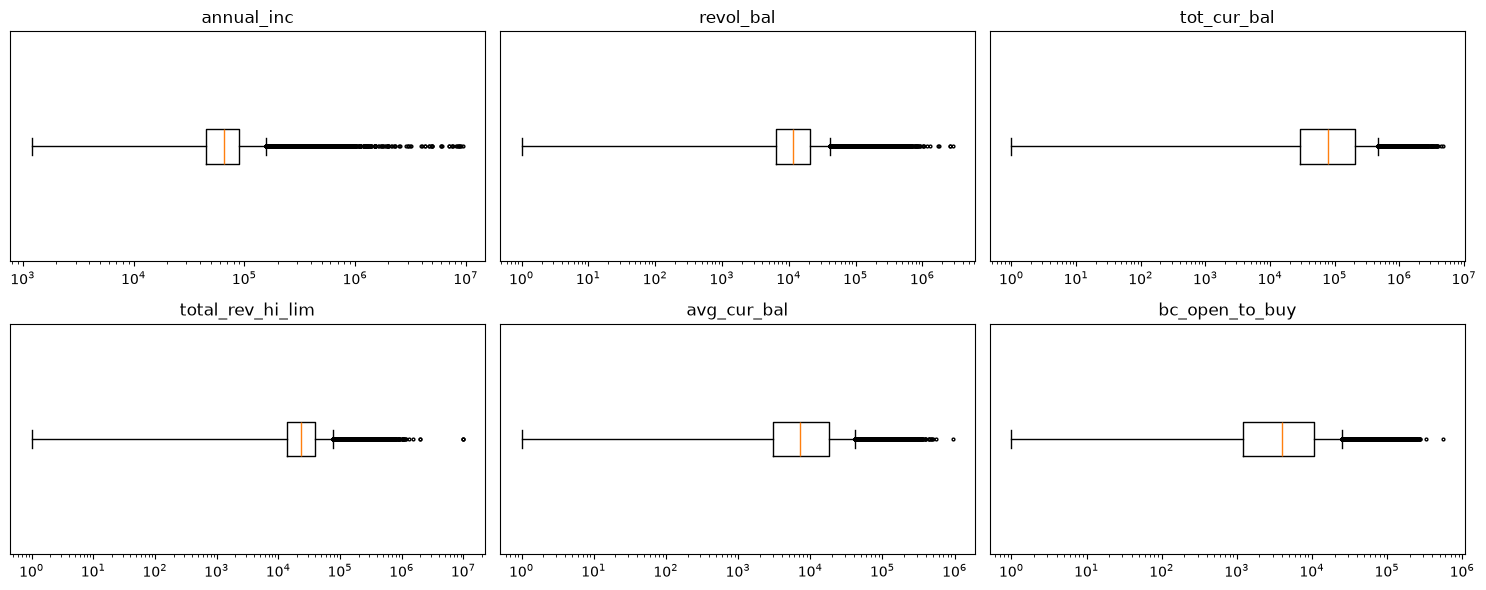

In [25]:
cols = ["annual_inc", "revol_bal", "tot_cur_bal", "total_rev_hi_lim", "avg_cur_bal", "bc_open_to_buy"]
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, c in zip(axes.ravel(), cols):
    ax.boxplot(tr[c].dropna().clip(lower=1), orientation="horizontal", flierprops={"markersize": 2})
    ax.set_xscale("log")
    ax.set_title(c)
    ax.set_yticks([])
plt.tight_layout()
plt.show()

### 5.2 Обработка выбросов

**Решение:** Значения выше 99.9-го перцентиля заменяем на значение этого перцентиля.

**Почему так:**
- Строки не удаляем: каждый признак затрагивает около 0.1% строк, а дефолты среди крупных заемщиков нужны модели.
- Нижние хвосты не трогаем: признаки ограничены нулем.
- Границы считаем только по обучающей выборке и применяем к val и test без пересчета, чтобы не было утечки.
- Заглушка 9 999 999 в `total_rev_hi_lim` обрезается этой же процедурой.

**Что не обрабатываем:** Флаги и `target`, колонки `mths_since_*` (наша заглушка 999), `fico_range_*` и `loan_amnt` (ограничены продуктом), а также признаки с числом уникальных значений меньше 20: у малых счетчиков p99.9 может быть равен 0 (например, у `num_tl_120dpd_2m`), и обрезка уничтожила бы весь сигнал.

**Дальше:** Логарифмирование денежных признаков - на этапе feature engineering, для линейных моделей и нейросетей. Деревья и CatBoost к монотонным преобразованиям нечувствительны. Эффект винсоризации проверим в экспериментах.

In [26]:
def fit_clip_bounds(df, q=0.999):
    cols = [c for c in features
            if c in df.columns
            and pd.api.types.is_numeric_dtype(df[c])
            and not c.startswith("mths_since_")
            and not c.startswith("fico_range")
            and c != "loan_amnt"
            and df[c].nunique() >= 20]
    return df[cols].quantile(q)


def clip_outliers(df, bounds):
    df = df.copy()
    df[bounds.index] = df[bounds.index].clip(upper=bounds, axis=1)
    return df

**Проверка:** Границы, максимумы до обрезки и число обрезанных значений на обучающей части.

In [27]:
bounds = fit_clip_bounds(tr)
clipped = pd.DataFrame({
    "Граница (p99.9)": bounds,
    "Max до обрезки": tr[bounds.index].max(),
    "Обрезано значений": (tr[bounds.index] > bounds).sum(),
})
clipped.sort_values("Max до обрезки", ascending=False).round(1)

,Граница (p99.9),Max до обрезки,Обрезано значений
total_rev_hi_lim,333000.0,9999999.0,733
annual_inc,536104.0,9500000.0,734
tot_hi_cred_lim,1349478.8,8700253.0,734
tot_cur_bal,1199929.2,4772549.0,734
total_bal_ex_mort,419484.3,2921551.0,734
revol_bal,264713.8,2904836.0,734
total_il_high_credit_limit,350325.5,2101913.0,734
avg_cur_bal,138370.2,958084.0,734
total_bc_limit,163000.0,760000.0,733
bc_open_to_buy,124739.0,559912.0,727


## 6. Функции очистки и разбиение выборки

### 6.1 Заполнение пропусков

Собираем решения из разделов 3-4 в функцию `handle_missing`. Медианы считаются только по обучающей части и применяются к val и test без пересчета.

In [28]:
def handle_missing(df, train_medians=None):
    df = df[df["issue_d"] >= "2013-01-01"].copy()
    df = fix_errors(df)

    no_action = ["mths_since_last_record", "mths_since_last_delinq",
             "mths_since_last_major_derog", "mths_since_recent_bc_dlq",
             "mths_since_recent_revol_delinq", "mths_since_recent_inq",
             "mths_since_recent_bc"]
    for c in no_action:
        df[c + "_na"] = df[c].isna().astype(int)
        df[c] = df[c].fillna(999)

    df["has_bc"] = (df["num_bc_tl"] > 0).astype(int)
    df[["bc_util", "percent_bc_gt_75", "bc_open_to_buy"]] = df[["bc_util", "percent_bc_gt_75", "bc_open_to_buy"]].fillna(0)
    df["mo_sin_old_il_acct"] = df["mo_sin_old_il_acct"].fillna(0)
    df["revol_util"] = df["revol_util"].fillna(0)

    df["emp_length"] = df["emp_length"].fillna("unknown")
    df["num_tl_120dpd_2m_na"] = df["num_tl_120dpd_2m"].isna().astype(int)

    num_cols = df.select_dtypes("number").columns
    if train_medians is None:
        train_medians = df[num_cols].median()
    df[num_cols] = df[num_cols].fillna(train_medians)
    return df, train_medians

### 6.2 Разбиение по времени и очистка

Разбиваем данные на обучающие (до 2016 года), проверочные (2016) и тестовые (2017). После этого проводим очистку: заполнение пропусков функцией `handle_missing` и обрезку выбросов функцией `clip_outliers` (границы по обучающей части). 2018 год в проверочные и тестовые данные не входит: большинство займов еще не погашено, и доля дефолтов занижена.

In [29]:
train = df[df["issue_d"] < "2016-01-01"]
val   = df[(df["issue_d"] >= "2016-01-01") & (df["issue_d"] < "2017-01-01")]
test  = df[(df["issue_d"] >= "2017-01-01") & (df["issue_d"] < "2018-01-01")]

train_clean, medians = handle_missing(train)
val_clean,  _ = handle_missing(val,  medians)
test_clean, _ = handle_missing(test, medians)

bounds = fit_clip_bounds(train_clean)
train_clean = clip_outliers(train_clean, bounds)
val_clean = clip_outliers(val_clean, bounds)
test_clean = clip_outliers(test_clean, bounds)

print("Пустых значений в train/val/test_clean:")
print(train_clean.isna().sum().sum(), val_clean.isna().sum().sum(), test_clean.isna().sum().sum())

Пустых значений в train/val/test_clean:
0 0 0


## 7. Связь признаков с целевой переменной

### 7.1 Выборка для анализа

Анализируем только обучающую часть (2013-2015 годы) после очистки: `train_clean` из 6.2. Проверочные и тестовые данные не используем, чтобы выводы не подглядывали в будущее.

Добавляем два предварительных признака: `credit_history_years` - длина кредитной истории на момент выдачи в годах - и `payment_to_income` - отношение годовой суммы платежей к годовому доходу. Окончательно признаки оформим на этапе feature engineering.

In [30]:
train_clean["credit_history_years"] = (train_clean["issue_d"] - train_clean["earliest_cr_line"]).dt.days / 365.25
train_clean["payment_to_income"] = train_clean["installment"] * 12 / train_clean["annual_inc"]
print("Обучающая выборка после очистки:", train_clean.shape)

Обучающая выборка после очистки: (733451, 74)


### 7.2 Целевая переменная

Смотрим на баланс классов и на то, как доля дефолтов меняется по годам выдачи.

In [31]:
by_year = train_clean.groupby(train_clean["issue_d"].dt.year)["target"].agg(n="size", default_share="mean")
by_year["default_share"] = (by_year["default_share"] * 100).round(1)
print(f"Доля дефолтов в обучающей выборке: {train_clean['target'].mean() * 100:.1f}%")
print(by_year.astype(object).T.to_string())

Доля дефолтов в обучающей выборке: 18.8%
issue_d          2013    2014    2015
n              134804  223102  375545
default_share    15.6    18.4    20.2


**Вывод.** Дефолтом закончилось 18.8% займов, классы несбалансированы умеренно (примерно 1 к 4). Доля дефолтов растет с каждым годом выдачи: 15.6% в 2013, 18.4% в 2014, 20.2% в 2015, поэтому разбиение по времени обязательно, а метрики - ROC-AUC и PR-AUC, а не accuracy.

### 7.3 Числовые признаки и таргет

**Метод.** Для каждого числового признака считаем ROC-AUC одного этого признака, корреляцию Спирмена с таргетом и медианы по классам. AUC показывает вероятность того, что у случайного заемщика с дефолтом значение признака выше, чем у случайного заемщика без дефолта: 0.5 - связи нет, меньше 0.5 - чем выше значение, тем реже дефолт. Показаны 15 признаков с наибольшей связью.

In [32]:
flag_cols = [c for c in train_clean.columns if c.endswith("_na") or c == "has_bc"]
num_feats = [c for c in train_clean.select_dtypes("number").columns if c != "target"]
y = train_clean["target"]
n1 = y.sum()
n0 = len(y) - n1

rows = {}
for c in num_feats:
    r = train_clean[c].rank()
    rows[c] = {
        "AUC": (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0),
        "Spearman": r.corr(y),
        "медиана, target=0": train_clean.loc[y == 0, c].median(),
        "медиана, target=1": train_clean.loc[y == 1, c].median(),
    }
uni = pd.DataFrame(rows).T
uni["|AUC - 0.5|"] = (uni["AUC"] - 0.5).abs()
uni = uni.sort_values("|AUC - 0.5|", ascending=False)
uni.head(15).round(3)

,AUC,Spearman,"медиана, target=0","медиана, target=1",|AUC - 0.5|
fico_range_low,0.412,-0.119,690.000,680.000,0.088
fico_range_high,0.412,-0.119,694.000,684.000,0.088
acc_open_past_24mths,0.582,0.112,4.000,5.000,0.082
payment_to_income,0.581,0.110,0.072,0.086,0.081
dti,0.580,0.108,17.330,20.000,0.080
num_tl_op_past_12m,0.570,0.097,2.000,2.000,0.070
bc_open_to_buy,0.437,-0.085,4174.000,2956.000,0.063
mo_sin_rcnt_tl,0.444,-0.076,6.000,5.000,0.056
mths_since_recent_inq,0.446,-0.073,6.000,5.000,0.054
total_bc_limit,0.447,-0.072,15000.000,12500.000,0.053


**Вывод.**
- Сильнее всего с дефолтом связан `fico_range_low` (AUC 0.412, то есть 0.588 в обратную сторону): чем выше скоринговый балл, тем реже дефолт. Следом идут `acc_open_past_24mths` (0.582), новый `payment_to_income` (0.581) и `dti` (0.580): чем больше недавно открытых счетов и выше долговая нагрузка, тем чаще дефолт.
- Ни один признак по отдельности не превышает 0.59. Связи слабые, и среди них нет подозрительно сильных, то есть отбор утекающих колонок сработал.
- Признаки, где почти все значения нулевые (`num_tl_120dpd_2m`, `acc_now_delinq`) или которые редко равны 1 (флаги пропусков), дают AUC около 0.50. Это свойство самой метрики на редких значениях, а не доказательство бесполезности: такие признаки оцениваем по доле дефолтов в группах.
- Длина кредитной истории слабее (AUC около 0.47), но направление понятное: длиннее история - реже дефолт.

### 7.4 Форма зависимости

Делим признак на 10 групп поровну и считаем долю дефолтов в каждой группе. Пунктир - общая доля дефолтов.

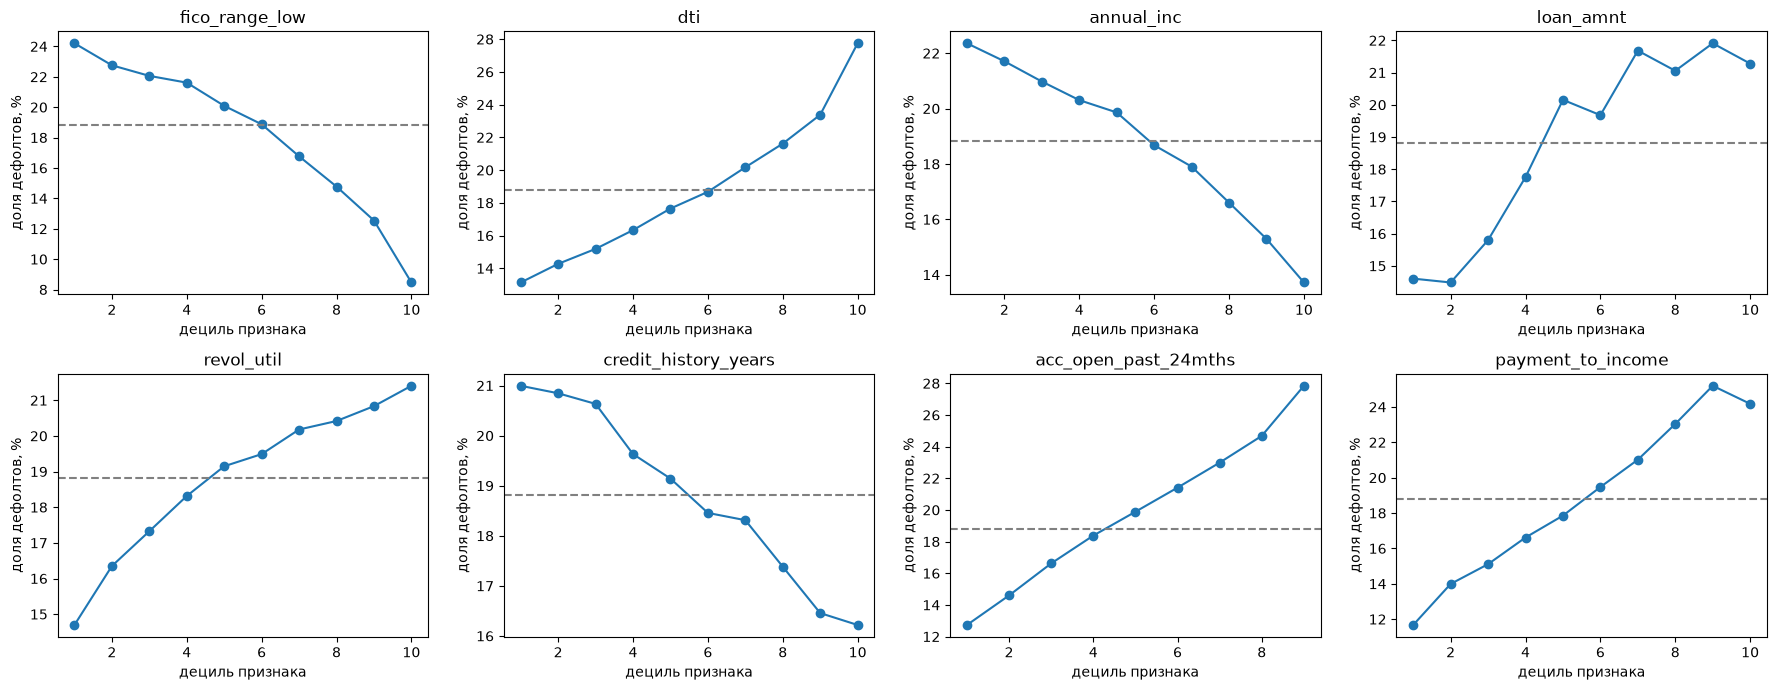

In [33]:
cols = ["fico_range_low", "dti", "annual_inc", "loan_amnt",
        "revol_util", "credit_history_years", "acc_open_past_24mths", "payment_to_income"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), cols):
    g = train_clean.groupby(pd.qcut(train_clean[c], 10, duplicates="drop"), observed=True)["target"].mean() * 100
    ax.plot(range(1, len(g) + 1), g.values, marker="o")
    ax.axhline(train_clean["target"].mean() * 100, color="gray", linestyle="--")
    ax.set_title(c)
    ax.set_xlabel("дециль признака")
    ax.set_ylabel("доля дефолтов, %")
plt.tight_layout()
plt.show()

**Вывод.**
- `fico_range_low`: доля дефолтов монотонно падает с 24.2% в нижней группе до 8.5% в верхней.
- `dti`: растет с 13.1% до 27.7%. `acc_open_past_24mths`: с 12.7% до 27.8%. `revol_util`: с 14.7% до 21.4%.
- `annual_inc`: падает с 22.4% до 13.7%. `credit_history_years`: с 21.0% до 16.2%.
- Зависимости монотонные и плавные, поэтому подходят и деревьям, и линейным моделям после преобразований.
- `loan_amnt`: доля дефолтов растет с 14.6% примерно до 22%, дальше плато. Причина - срок займа, см. 7.8.

### 7.5 Категориальные признаки и таргет

Доля дефолтов по категориям.

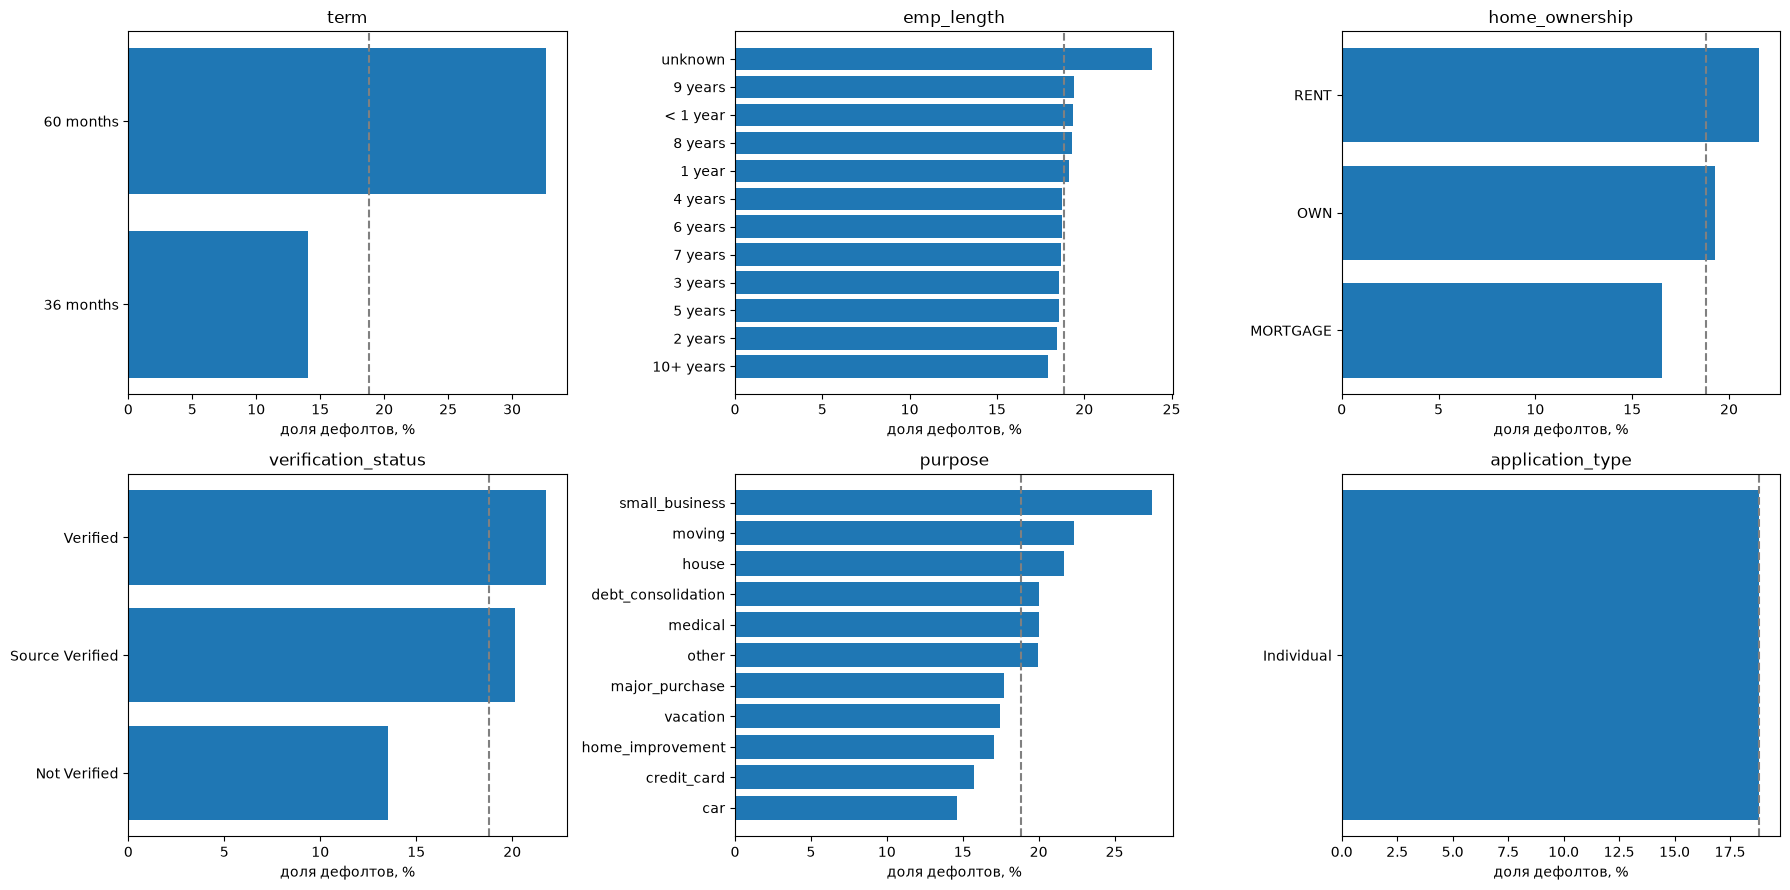

{'home_ownership': {'ANY': 3},
 'purpose': {'wedding': 607, 'renewable_energy': 384, 'educational': 1},
 'application_type': {'Joint App': 401}}

In [34]:
cat_cols = ["term", "emp_length", "home_ownership", "verification_status", "purpose", "application_type"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, c in zip(axes.ravel(), cat_cols):
    g = train_clean.groupby(c)["target"].agg(["mean", "size"]).sort_values("mean")
    g = g[g["size"] >= 1000]
    ax.barh(g.index.astype(str), g["mean"] * 100)
    ax.axvline(train_clean["target"].mean() * 100, color="gray", linestyle="--")
    ax.set_title(c)
    ax.set_xlabel("доля дефолтов, %")
plt.tight_layout()
plt.show()

rare = {c: train_clean[c].value_counts().loc[lambda s: s < 1000].to_dict() for c in cat_cols}
{c: v for c, v in rare.items() if v}

**Вывод.**
- `term`: 36 месяцев - 14.1% дефолтов, 60 месяцев - 32.6%. Это самый сильный признак из всех, и займов на 60 месяцев четверть.
- `home_ownership`: аренда 21.6%, собственное жилье 19.3%, ипотека 16.5%.
- `verification_status`: у неверифицированных доход дефолт реже (13.6%), чем у верифицированных (21.7%). Это не причинная связь: проверку дохода, вероятно, запрашивают у более рисковых клиентов. Признак оставляем, но интерпретируем осторожно.
- `purpose`: выше всего риск у `small_business` (27.5%), ниже всего у `credit_card` (15.8%) и `home_improvement` (17.1%). `debt_consolidation` - 20.0%, и это 60% выборки.
- `emp_length`: у известных значений доли дефолтов почти одинаковые (17.9-19.4%), заметно выделяется только `unknown` (23.9%).
- Редкие категории: `ANY`, `educational`, `wedding`, `renewable_energy`, тип заявки `Joint App`. Их нужно объединить или использовать с осторожностью.

### 7.6 Корреляции между признаками

Считаем корреляцию Спирмена на случайных 200 000 строк. Флаги и колонки `mths_since_*` исключены: в последних заглушка 999 искажает ранги.

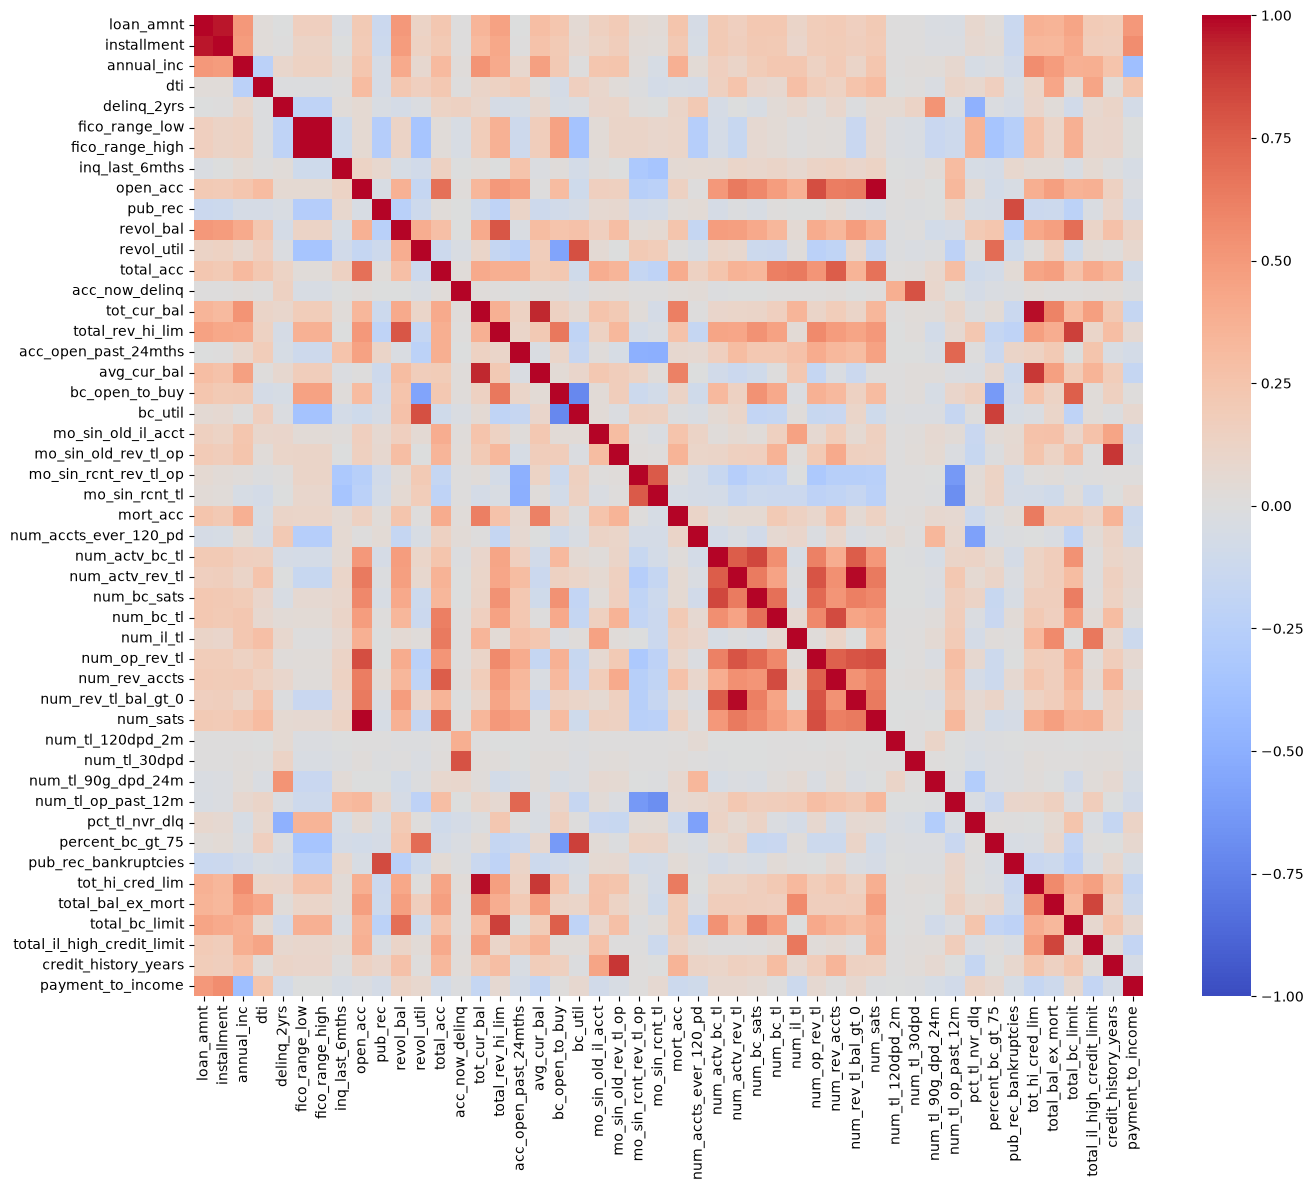

In [35]:
corr_cols = [c for c in num_feats if c not in flag_cols and not c.startswith("mths_since_")]
corr = train_clean[corr_cols].sample(200000, random_state=0).corr(method="spearman")

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
plt.tight_layout()
plt.show()

In [36]:
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.where(mask).stack().rename("rho").reset_index()
pairs.columns = ["признак 1", "признак 2", "rho"]
pairs["|rho|"] = pairs["rho"].abs()
print("Пар с |rho| >= 0.9:", (pairs["|rho|"] >= 0.9).sum(), "| с |rho| >= 0.8:", (pairs["|rho|"] >= 0.8).sum())
pairs.sort_values("|rho|", ascending=False).head(12).round(3)

Пар с |rho| >= 0.9: 6 | с |rho| >= 0.8: 18


,признак 1,признак 2,rho,|rho|
246,fico_range_low,fico_range_high,1.000,1.000
418,open_acc,num_sats,0.998,0.998
1329,num_actv_rev_tl,num_rev_tl_bal_gt_0,0.990,0.990
714,tot_cur_bal,tot_hi_cred_lim,0.977,0.977
1,loan_amnt,installment,0.966,0.966
689,tot_cur_bal,avg_cur_bal,0.930,0.930
1054,mo_sin_old_rev_tl_op,credit_history_years,0.898,0.898
858,avg_cur_bal,tot_hi_cred_lim,0.889,0.889
952,bc_util,percent_bc_gt_75,0.863,0.863
764,total_rev_hi_lim,total_bc_limit,0.863,0.863


**Вывод.** Пар с |rho| не меньше 0.9 - 6, не меньше 0.8 - 18. Самые сильные:
- `fico_range_low` и `fico_range_high` (1.0) - практически дубли;
- `open_acc` и `num_sats` (0.998), `num_actv_rev_tl` и `num_rev_tl_bal_gt_0` (0.990);
- `tot_cur_bal` и `tot_hi_cred_lim` (0.977), `loan_amnt` и `installment` (0.966);
- `tot_cur_bal` и `avg_cur_bal` (0.930), `mo_sin_old_rev_tl_op` и новый `credit_history_years` (0.898).

Для линейных моделей и нейросетей такие пары дают мультиколлинеарность и нестабильные коэффициенты. Деревьям они почти не мешают, но делят важность между дублями.

### 7.7 Pairplot

Парные диаграммы по 6 ключевым признакам на 3 000 случайных строк, `annual_inc` в логарифме, цвет - значение `target`.

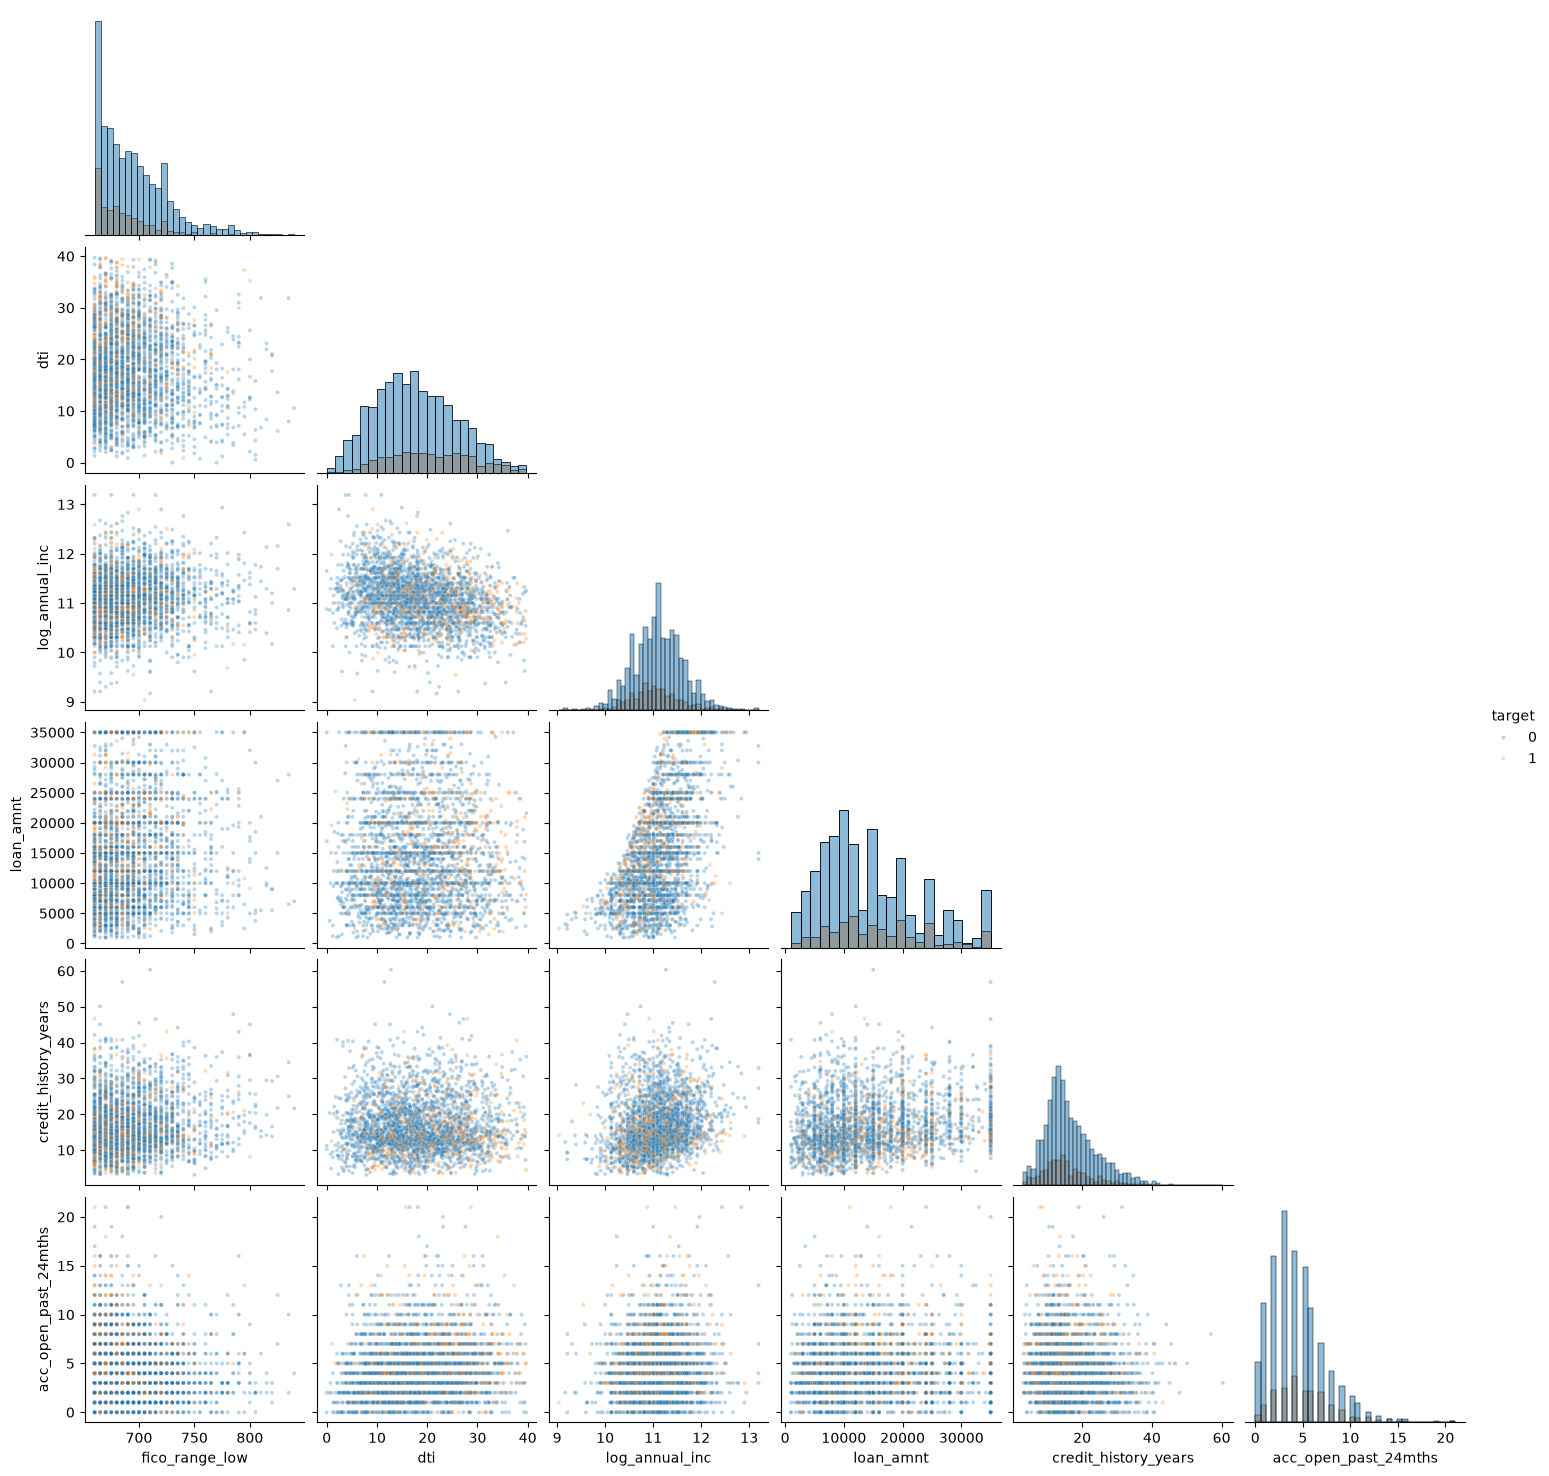

In [37]:
sample = train_clean.sample(3000, random_state=0).copy()
sample["log_annual_inc"] = np.log1p(sample["annual_inc"])
vars_ = ["fico_range_low", "dti", "log_annual_inc", "loan_amnt", "credit_history_years", "acc_open_past_24mths"]
sns.pairplot(sample, vars=vars_, hue="target", corner=True, diag_kind="hist",
             plot_kws={"alpha": 0.3, "s": 8})
plt.show()

**Вывод.** Классы на парах признаков сильно перекрываются, визуального разделения нет. Это согласуется с AUC одиночных признаков (не выше 0.59): сигнал складывается из многих слабых признаков, и ожидать от модели очень высокого качества не стоит.

### 7.8 Сводные таблицы

Смотрим доли дефолтов по сочетаниям признаков и проверяем, складываются ли эффекты.

**FICO и DTI.**

In [38]:
d = train_clean.copy()
d["fico_bin"] = pd.cut(d["fico_range_low"], [600, 660, 680, 700, 720, 740, 900], right=False)
d["dti_bin"] = pd.cut(d["dti"], [0, 10, 20, 30, 100], right=False)

rate = d.pivot_table(index="fico_bin", columns="dti_bin", values="target", aggfunc="mean", observed=True) * 100
size = d.pivot_table(index="fico_bin", columns="dti_bin", values="target", aggfunc="size", observed=True)
print("Доля дефолтов, %: FICO (строки) x DTI (столбцы)")
display(rate.round(1))
print("Число займов")
display(size)

Доля дефолтов, %: FICO (строки) x DTI (столбцы)


dti_bin,"[0, 10)","[10, 20)","[20, 30)","[30, 100)"
fico_bin,,,,
"[660, 680)",16.7,21.4,26.9,33.3
"[680, 700)",14.5,17.7,22.7,28.8
"[700, 720)",11.9,13.7,18.0,24.0
"[720, 740)",9.8,10.7,14.3,20.1
"[740, 900)",6.8,7.3,10.8,14.6


Число займов


dti_bin,"[0, 10)","[10, 20)","[20, 30)","[30, 100)"
fico_bin,,,,
"[660, 680)",47601,112822,81200,24961
"[680, 700)",31301,85997,66783,20937
"[700, 720)",20015,55536,44396,13761
"[720, 740)",10827,28227,20808,5998
"[740, 900)",16386,26528,15688,3679


**Срок и цель займа.** Показаны цели с числом займов не меньше 1 000.

In [39]:
big = d["purpose"].value_counts().loc[lambda s: s >= 1000].index
sub = d[d["purpose"].isin(big)]
rate = sub.pivot_table(index="purpose", columns="term", values="target", aggfunc="mean") * 100
size = sub.pivot_table(index="purpose", columns="term", values="target", aggfunc="size")
out = pd.concat({"доля дефолтов, %": rate.round(1), "число займов": size}, axis=1)
out.sort_values(("доля дефолтов, %", " 36 months"))

доля дефолтов, %           число займов          
term                      36 months 60 months    36 months 60 months
purpose                                                             
credit_card                    11.7      30.0       136850     38598
car                            12.1      30.0         5183       838
home_improvement               12.7      29.3        31253     11164
major_purchase                 13.5      33.8        10060      2656
debt_consolidation             14.7      33.3       313370    124373
vacation                       15.9      39.8         3658       259
other                          16.4      37.7        28164      5607
medical                        17.4      34.7         5799      1040
house                          18.6      30.3         2008       722
moving                         19.9      41.4         3760       481
small_business                 22.9      42.5         5072      1544

**Срок и сумма займа.**

In [40]:
d["amnt_bin"] = pd.cut(d["loan_amnt"], [0, 5000, 10000, 20000, 40000])
rate = d.pivot_table(index="amnt_bin", columns="term", values="target", aggfunc="mean", observed=True) * 100
size = d.pivot_table(index="amnt_bin", columns="term", values="target", aggfunc="size", observed=True)
print("Доля дефолтов, %: сумма займа (строки) x срок (столбцы)")
display(rate.round(1))
print("Число займов")
display(size)

Доля дефолтов, %: сумма займа (строки) x срок (столбцы)


term,36 months,60 months
amnt_bin,,
"(0, 5000]",14.6,21.9
"(5000, 10000]",14.9,32.6
"(10000, 20000]",13.7,33.8
"(20000, 40000]",12.4,31.2


Число займов


term,36 months,60 months
amnt_bin,,
"(0, 5000]",84127,521
"(5000, 10000]",190742,9003
"(10000, 20000]",188202,98658
"(20000, 40000]",82947,79251


**Владение жильем, верификация дохода, год выдачи.**

In [41]:
sub = d[d["home_ownership"].isin(["MORTGAGE", "OWN", "RENT"])]
rate = sub.pivot_table(index="home_ownership", columns="verification_status", values="target", aggfunc="mean") * 100
print("Доля дефолтов, %: владение жильем (строки) x верификация дохода (столбцы)")
display(rate.round(1))
rate = d.pivot_table(index=d["issue_d"].dt.year.rename("год"), columns="term", values="target", aggfunc="mean") * 100
print("Доля дефолтов, %: год выдачи (строки) x срок (столбцы)")
display(rate.round(1))

Доля дефолтов, %: владение жильем (строки) x верификация дохода (столбцы)


verification_status,Not Verified,Source Verified,Verified
home_ownership,,,
MORTGAGE,12.1,17.4,19.2
OWN,14.2,20.6,22.0
RENT,15.2,23.2,25.2


Доля дефолтов, %: год выдачи (строки) x срок (столбцы)


term,36 months,60 months
год,,
2013,12.3,25.1
2014,13.7,31.1
2015,14.9,36.4


**Вывод.**
- FICO и DTI работают вместе: доля дефолтов от 6.8% (FICO 740 и выше, DTI до 10) до 33.3% (FICO 660-680, DTI от 30), разброс почти в 5 раз. Рост монотонный и по строкам, и по столбцам.
- Займы на 60 месяцев при любой цели дефолтятся в 2-3 раза чаще, чем на 36 (`credit_card`: 11.7% и 30.0%, `small_business`: 22.9% и 42.5%). Порядок целей от срока почти не зависит.
- Положительная связь `loan_amnt` с дефолтом - следствие срока: длинные займы крупнее. Внутри 36 месяцев с ростом суммы доля дефолтов падает с 14.6% до 12.4%, внутри 60 месяцев она держится около 31-34% (кроме займов до 5 000, их всего 521).
- Порядок `RENT` > `OWN` > `MORTGAGE` сохраняется внутри каждой группы верификации, а у неверифицированных доля дефолтов ниже во всех группах (12.1-15.2% против 19.2-25.2% у верифицированных). То есть эффекты независимы.
- Внутри каждого срока доля дефолтов растет от года к году: 36 месяцев - 12.3%, 13.7%, 14.9%; 60 месяцев - 25.1%, 31.1%, 36.4%. Рост не объясняется только увеличением доли длинных займов, это сдвиг в качестве выдач.

## 8. Выводы

### 8.1 Качество данных

- В обучающей выборке 733 451 займ (2013-2015 годы), доля дефолтов 18.8%. Данные до 2013 года отброшены (около 7% строк): у них целые блоки признаков бюро пусты из-за эпохи сбора данных.
- Пропуски: 8.77% ячеек, 97.9% строк содержат хотя бы один. Большинство - осмысленные: в `mths_since_*` пропуск означает "события не было", в `bc_*` и `mo_sin_old_il_acct` - "нет объекта", в `emp_length` и `num_tl_120dpd_2m` сам пропуск связан с риском. Остальное заполняем медианой обучающей выборки.
- Ошибки: `annual_inc = 0`, `dti < 0` и `dti >= 999`, заглушка `tot_hi_cred_lim = 9999999` заменены на `NaN`, одна строка с `open_acc > total_acc` удалена.
- Выбросы: тяжелые правые хвосты у денежных признаков и счетчиков. Режем сверху по 99.9-му перцентилю обучающей выборки.

### 8.2 Что связано с дефолтом

- Сильнее всего: срок займа (14.1% против 32.6%), скоринговый балл FICO, долговая нагрузка (`dti`, `payment_to_income`), число недавно открытых счетов, годовой доход, цель займа (`small_business` рискованнее всего), аренда жилья.
- Слабее: стаж работы (выделяется только `unknown`), длина кредитной истории.
- Ни один признак по отдельности не сильнее AUC 0.59, классы сильно перекрываются. Качество модели будет определяться сочетанием многих слабых сигналов.
- Доля дефолтов растет от года к году внутри каждого срока, то есть есть дрейф.

### 8.3 Как используем выводы

| Наблюдение | Что делаем дальше |
|---|---|
| Доля дефолтов дрейфует во времени (15.6% -> 20.2%, в 2016-2017 около 23%) | Разбиение по времени (train до 2016, val 2016, test 2017). Метрики ROC-AUC и PR-AUC, калибровка вероятностей на val. Год выдачи в признаки не берем, дрейф отслеживаем в сервисе |
| Умеренный дисбаланс классов (1 к 4) | Веса классов и подбор порога, SMOTE проверяем только на train |
| Слабые одиночные связи, сигнал в сочетаниях | Основная модель - градиентный бустинг (CatBoost), логистическая регрессия - базовая линия |
| Монотонные зависимости (FICO, DTI, доход) | Для логистической регрессии - биннинг/WOE или сплайны, для CatBoost можно проверить монотонные ограничения |
| Почти дубли: `fico_range_low/high`, `open_acc/num_sats`, `num_actv_rev_tl/num_rev_tl_bal_gt_0`, `tot_cur_bal/tot_hi_cred_lim`, `loan_amnt/installment` | Заменяем `fico_range_*` на среднее, из остальных пар для линейных моделей и нейросетей оставляем по одному признаку, для деревьев проверяем в абляции |
| Тяжелые хвосты денежных признаков | Ограничение сверху по p99.9 (раздел 5), для линейных моделей и нейросетей - `log1p` |
| Срок и сумма займа действуют вместе | Признак-взаимодействие срока и суммы, `loan_to_income`, `payment_to_income` |
| Редкие категории (`ANY`, `educational`, `wedding`, `renewable_energy`, `Joint App`) | Объединяем в `other`; `emp_length` - порядковый признак с отдельным `unknown`; `term` - число 36/60 |
| `verification_status` не причинный | Оставляем, но интерпретацию делаем осторожно, вклад проверяем в абляции |
| `credit_history_years` и `payment_to_income` дали сигнал | Добавляем в набор признаков на этапе feature engineering |
| 22 отложенных признака (`int_rate`, `grade`, `sub_grade` и др.) | Также проверяем в экспериментах по абляции |